# Cat and Dog Facial Feature Classification

**Goal:** To train a deep learning model that looks at an image and decides which of 8 classes it belongs to (CatEye, DogEye, CatFace, DogFace, CatMouth, DogMouth, CatNose, DogNose).



### Task 1: Dataset Exploration and Understanding

In [ ]:
import random, time, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn

# For reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

# Checking for my device for gpu
# Switches on mixed precision for saving memory and time
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
USE_AMP = device.type == "cuda"      # float16 mixed precision (faster, less memory)

DATA_DIR = Path(".")
RAW_TRAIN, RAW_TEST = DATA_DIR / "train", DATA_DIR / "test"

Using device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


In [ ]:
# Loads the label
labels_df = pd.read_csv(DATA_DIR / "train_labels.csv", dtype=str)   # keeps IDs like 00001
id_col, class_col = labels_df.columns[0], labels_df.columns[1]

# Encodes the classes/labels
classes = sorted(labels_df[class_col].unique())                     # 8 class names
class_to_idx = {c: i for i, c in enumerate(classes)}                # name -> number
labels_df["y"] = labels_df[class_col].map(class_to_idx)

print(labels_df.head())
print("Class -> number:", class_to_idx)
print("Images in CSV:", len(labels_df))

  image_id     class  y
0    00001    DogEye  4
1    00002  DogMouth  6
2    00003   DogFace  5
3    00004   DogNose  7
4    00005   DogNose  7
Class -> number: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Images in CSV: 63660


class
CatEye      13884
CatFace      6942
CatMouth     6942
CatNose      6942
DogEye      11580
DogFace      5790
DogMouth     5790
DogNose      5790
Name: count, dtype: int64
Imbalance ratio (max/min): 2.4


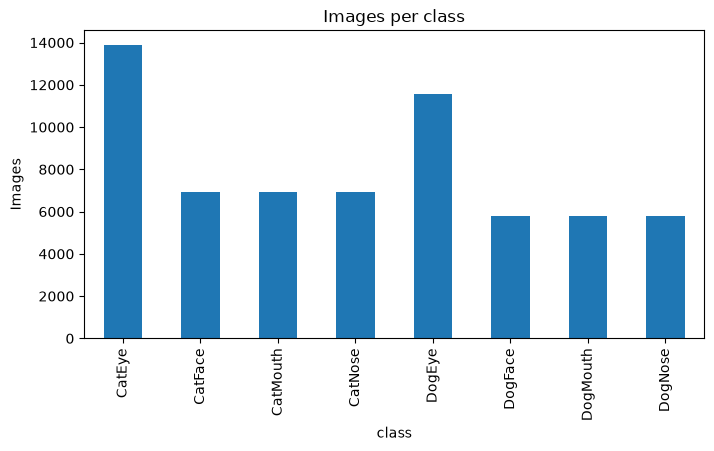

In [ ]:
# Class balance
# Bar chart visualization for class balance
counts = labels_df[class_col].value_counts().reindex(classes)
print(counts)
print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))
counts.plot(kind="bar", title="Images per class", figsize=(8, 4))
plt.ylabel("Images"); plt.show()

In [ ]:
# Function for a lookup table, acts like a dictionary
def build_lookup(folder):
    d = {}
    for p in folder.rglob("*"):
        if p.is_file():
            d[p.name] = p      # example: 00001.jpg
            d[p.stem] = p      # example: 00001
    return d

# Match train labels with their image files
train_files = build_lookup(RAW_TRAIN)
labels_df["raw_path"] = labels_df[id_col].map(train_files)
print("Labels with no image file (should be 0):", labels_df["raw_path"].isna().sum())
labels_df = labels_df.dropna(subset=["raw_path"]).reset_index(drop=True)

Labels with no image file (should be 0): 0


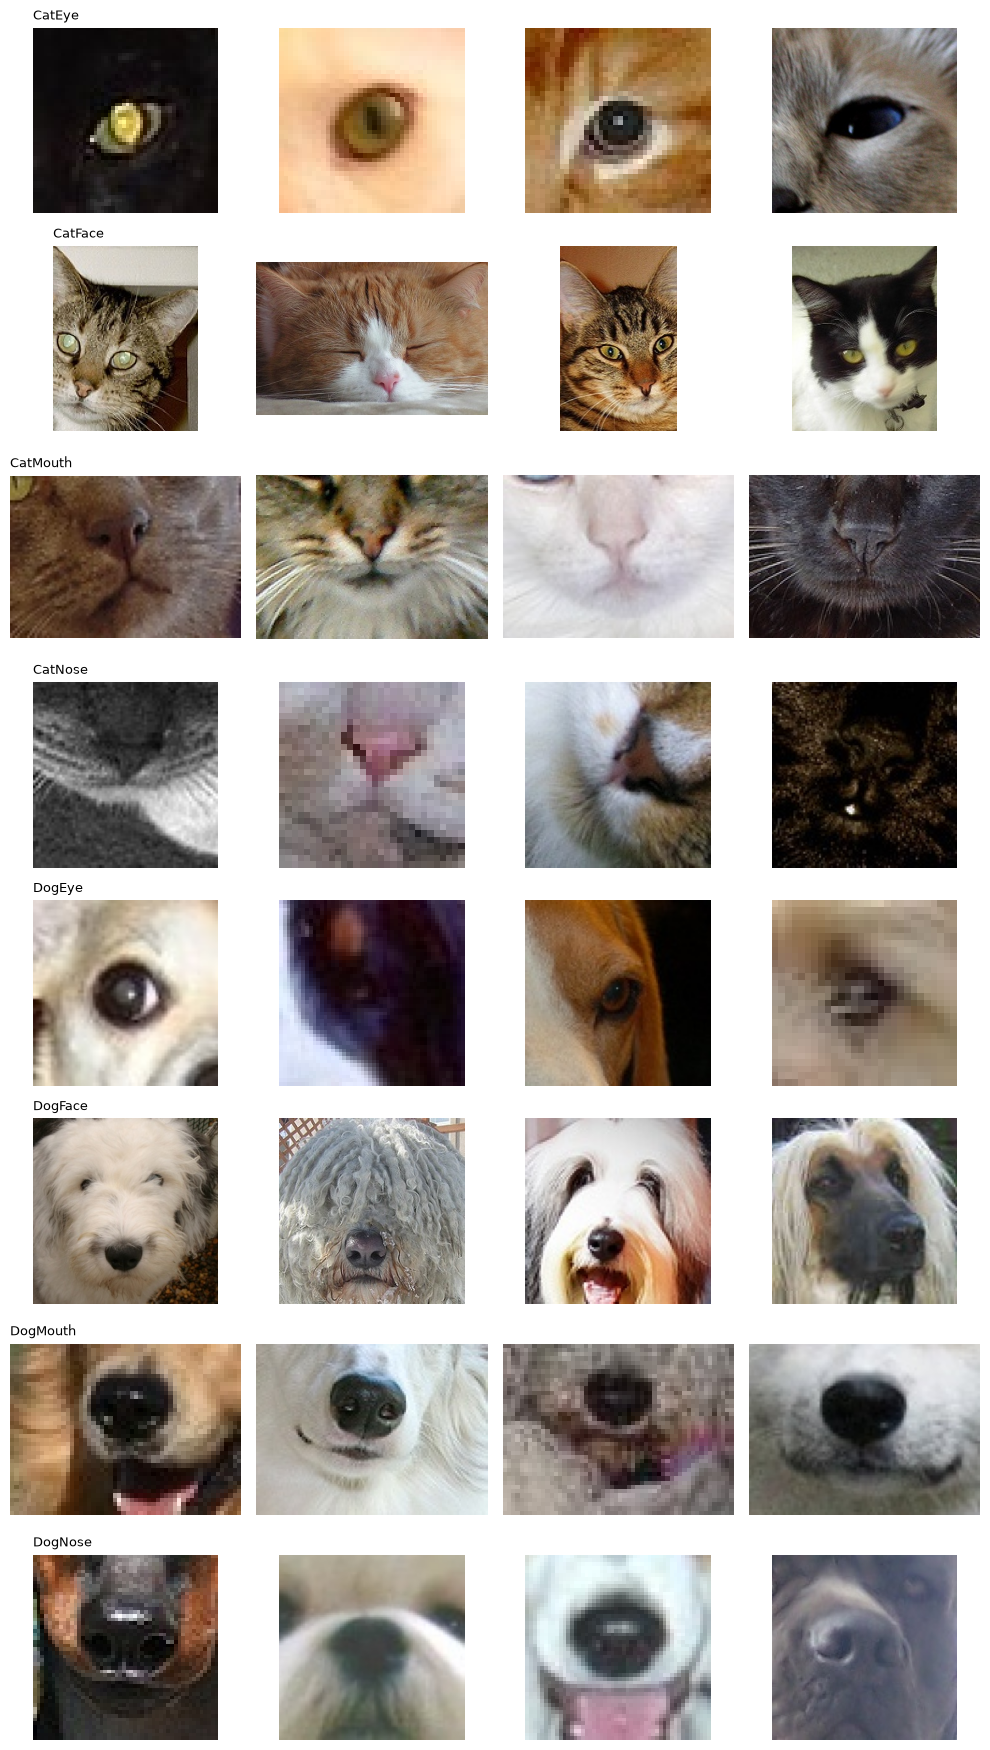

In [ ]:
# Library for loading and checking images
from PIL import Image

# Subplot diagram for four representative images from each class
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.2 * len(classes)))
for row, cls in enumerate(classes):
    samples = labels_df[labels_df[class_col] == cls].sample(4, random_state=SEED)["raw_path"]
    for col, path in enumerate(samples):
        axes[row, col].imshow(Image.open(path).convert("RGB"))
        axes[row, col].axis("off")
    axes[row, 0].set_title(cls, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
from collections import Counter

# Check for image dimensions
# Identify corrupted files
sizes, broken = Counter(), []
for path in labels_df["raw_path"]:
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            sizes[im.size] += 1
    except Exception:
        broken.append(path)

print("Corrupted files:", len(broken))
print("Different image sizes:", len(sizes))
print("Most common sizes:", sizes.most_common(5))
labels_df = labels_df[~labels_df["raw_path"].isin(broken)].reset_index(drop=True)

Corrupted files: 0
Different image sizes: 7861
Most common sizes: [((40, 40), 1062), ((48, 48), 1051), ((42, 42), 1050), ((38, 38), 1002), ((44, 44), 1002)]


In [ ]:
# Output size for resized test images
SMALL = 256   

# Resize images and mapping of image IDs to saved paths
def shrink(paths, out_dir):
    """Save resized copies of the images. Returns {image id: new path}. Skips files already done."""
    out_dir.mkdir(exist_ok=True)
    paths = list(paths)
    mapping = {}
    for i, p in enumerate(paths):
        dst = out_dir / (Path(p).stem + ".jpg")
        if not dst.exists():                         # skip images already resized
            with Image.open(p) as im:
                im.convert("RGB").resize((SMALL, SMALL)).save(dst, quality=95)
        mapping[Path(p).stem] = dst
        if i % 1000 == 0:
            print(f"  {i}/{len(paths)} done")
    return mapping

train_small = shrink(labels_df["raw_path"], DATA_DIR / "train_small")
labels_df["path"] = labels_df["raw_path"].map(lambda p: train_small[Path(p).stem])

# Load the sample submission to follow Kaggle's expected row order
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype=str)
sub_id_col, sub_class_col = sample_sub.columns[0], sample_sub.columns[1]

# Match test images using their ID so "1" matches "00001.jpg"
test_files = {}
for p in RAW_TEST.rglob("*"):
    if p.is_file() and p.stem.isdigit():
        test_files[int(p.stem)] = p

# Check if every submission ID has a matching test image
missing = [i for i in sample_sub[sub_id_col] if int(i) not in test_files]
print("Test IDs with no matching file (should be 0):", len(missing))

# Resize test images and store their path to dictionary
test_small = shrink([test_files[int(i)] for i in sample_sub[sub_id_col]], DATA_DIR / "test_small")
test_small = {int(k): v for k, v in test_small.items()}      # keys become numbers too

print("Training images:", len(labels_df), "| Test images:", len(test_small))

Test IDs with no matching file (should be 0): 0
  0/29443 done
  1000/29443 done
  2000/29443 done
  3000/29443 done
  4000/29443 done
  5000/29443 done
  6000/29443 done
  7000/29443 done
  8000/29443 done
  9000/29443 done
  10000/29443 done
  11000/29443 done
  12000/29443 done
  13000/29443 done
  14000/29443 done
  15000/29443 done
  16000/29443 done
  17000/29443 done
  18000/29443 done
  19000/29443 done
  20000/29443 done
  21000/29443 done
  22000/29443 done
  23000/29443 done
  24000/29443 done
  25000/29443 done
  26000/29443 done
  27000/29443 done
  28000/29443 done
  29000/29443 done
Training images: 63660 | Test images: 29443


#### How the dataset is used?
The training data (80%) is used to train the model, while the validation data (20%) is used to monitor performance and select the best model. The test data is used only for final predictions. These predictions are saved in submission.csv using the provided Kaggle template and uploaded for evaluation.

### Task 2: Data Preprocessing and Pipeline Preparation

In [ ]:
# Library for image transformation
# For preprocessing and augmentation
from torchvision import transforms

# Model input size and ImageNet normalisation values
IMG_SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics

# Applying random transformation to increase variation of training data
train_tf = transforms.Compose([                  # training: random augmentation
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Applying consistent transformation w/out augmentation during evaluation
eval_tf = transforms.Compose([                   # validation/test: no randomness
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

In [ ]:
# Libraries for splitting data and loading batch of images
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

# Dataset class for loading images and their labels
class ImgDS(Dataset):
    def __init__(self, df, transform):
        self.paths = df["path"].tolist()
        self.labels = df["y"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)          # returns the no. of images in dataset
    def __getitem__(self, i):
        return self.transform(Image.open(self.paths[i]).convert("RGB")), self.labels[i]     # Load an image, apply transformations, and return its label

# Split labeled data to stratified training and vaalidation sets
tr_df, va_df = train_test_split(labels_df, test_size=0.2, stratify=labels_df["y"], random_state=SEED)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)

# Set the batch size and no. of data loading workers
BATCH = 32
NUM_WORKERS = 0

# Training loader with shuffled batch
train_loader = DataLoader(ImgDS(tr_df, train_tf), batch_size=BATCH, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
# Validation loader w/out shuffle
val_loader = DataLoader(ImgDS(va_df, eval_tf), batch_size=BATCH,
                        num_workers=NUM_WORKERS, pin_memory=True)

# Check split sizes and batch dimensions
print("Training:", len(tr_df), "| Validation:", len(va_df))
x, y = next(iter(train_loader))
print("Batch shape:", x.shape)

Training: 50928 | Validation: 12732
Batch shape: torch.Size([32, 3, 224, 224])


### Task 3: Model Selection and Pipeline Development

In [ ]:
# Import prebuilt deeplearning models
from torchvision import models

# Load EfficientNet-B0 with ImageNet-pretrained weights
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)

# Replace the final layer with eight output classes
model.classifier[1] = nn.Linear(1280, len(classes))                              
model = model.to(device)

# Classification loss with label smoothing
loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)      # smoothing reduces overconfidence

print("Parameters (millions):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))
print("Model is on:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\John/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100.0%


Parameters (millions): 4.0
Model is on: cuda:0


In [ ]:
# Setting mixed-precision gradient scaling for GPU training
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

# Training the model for one epoch
def run_epoch(loader, train, optimizer=None, criterion=None):
    criterion = criterion or loss_fn
    model.train() if train else model.eval()
    total_loss, correct = 0.0, 0

    # Process each batch and move it to device
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)

        # Forward pass
        with torch.set_grad_enabled(train), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = model(x)
        loss = criterion(out.float(), y)          # calculate loss in full precision

        # Update model weights when training
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()         # backpropagation
            scaler.step(optimizer)                # update weights
            scaler.update()

        # Total loss and correct prediction
        total_loss += loss.item() * len(y)
        correct += (out.argmax(1) == y).sum().item()
    n = len(loader.dataset)         # average loss and accuracy for epoch
    return total_loss / n, correct / n

### Task 4: Training Strategy and Overfitting/Underfitting Management

In [ ]:
# Set the number of epochs for classifier training and fine-tuning
HEAD_EPOCHS = 2     # phase 1: only the new last layer learns
FT_EPOCHS = 8       # phase 2: whole model learns, learning rate decays

# Standard cross-entropy loss for validation
val_loss_fn = nn.CrossEntropyLoss()

# Store training and validation metrics for learning curves
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_acc = 0

# Record metrics and print the results after each epoch
def log(tag, ep, total, t0, tl, ta, vl, va):
    for k, v in zip(history, [tl, vl, ta, va]):
        history[k].append(v)
    print(f"{tag} {ep+1}/{total} | loss {tl:.3f}/{vl:.3f} | acc {ta:.3f}/{va:.3f} (train/val) | {time.time()-t0:.0f}s")

# Phase 1: freeze everything except the new last layer/classifier
for p in model.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

# Optimize the classifier with AdamW
opt = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=0.01)

# Train and validate classifier for initial phase
for ep in range(HEAD_EPOCHS):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True, opt)
    vl, va = run_epoch(val_loader, False, criterion=val_loss_fn)
    log("head", ep, HEAD_EPOCHS, t0, tl, ta, vl, va)

# Phase 2: unfreeze everything, smaller learning rate with cosine decay
for p in model.parameters():
    p.requires_grad = True

# Smaller learning rate and cosine learning-rate scheduler
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EPOCHS)

# Fine-tune model and save the best validation checkpoint
for ep in range(FT_EPOCHS):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True, opt)
    vl, va = run_epoch(val_loader, False, criterion=val_loss_fn)
    sched.step()
    log("fine-tune", ep, FT_EPOCHS, t0, tl, ta, vl, va)

    # Save model whenever validation accuracy improves
    if va > best_acc:
        best_acc = va
        torch.save(model.state_dict(), "best_model.pt")


# Load the best checkpoint and display its validation accuracy
model.load_state_dict(torch.load("best_model.pt", map_location=device))
print("Best validation accuracy:", round(best_acc, 4))

head 1/2 | loss 1.061/0.726 | acc 0.750/0.766 (train/val) | 981s
head 2/2 | loss 0.973/0.707 | acc 0.789/0.771 (train/val) | 506s
fine-tune 1/8 | loss 0.603/0.119 | acc 0.954/0.985 (train/val) | 918s
fine-tune 2/8 | loss 0.531/0.122 | acc 0.978/0.987 (train/val) | 914s
fine-tune 3/8 | loss 0.515/0.116 | acc 0.984/0.988 (train/val) | 911s
fine-tune 4/8 | loss 0.505/0.168 | acc 0.987/0.968 (train/val) | 915s
fine-tune 5/8 | loss 0.494/0.128 | acc 0.990/0.988 (train/val) | 19769s


KeyboardInterrupt: 

In [53]:
# Reload the best model before plotting and evaluation
model.load_state_dict(torch.load("best_model.pt", map_location=device))

<All keys matched successfully>

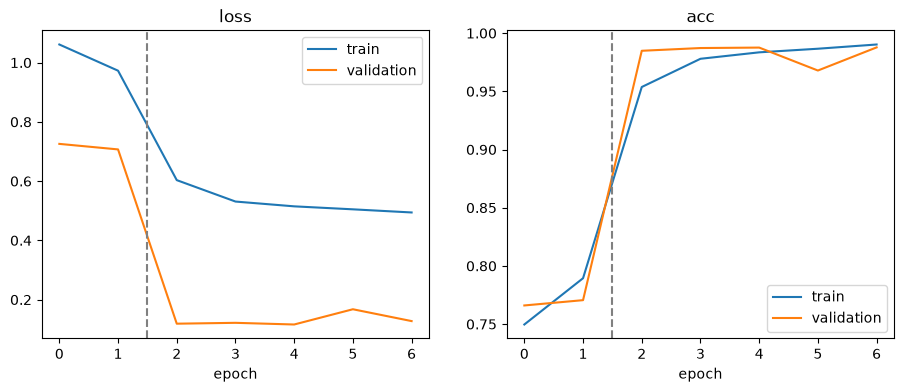

In [54]:
# Plot training and validation loss and accuracy across epochs
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, m in zip(ax, ["loss", "acc"]):
    a.plot(history[f"train_{m}"], label="train")
    a.plot(history[f"val_{m}"], label="validation")
    a.axvline(HEAD_EPOCHS - 0.5, ls="--", c="grey")      # where fine-tuning starts
    a.set_title(m); a.set_xlabel("epoch"); a.legend()
plt.show()

### Task 5: Model Evaluation and Kaggle Submission

In [ ]:
# Function for prediction probabilities without calculating gradients
@torch.no_grad()
def predict_proba(loader, flip=True):
    model.eval()
    out = []

    # Predict each batch
    for x, _ in loader:
        x = x.to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            p = model(x).float().softmax(1)
            if flip:                                              # average with the mirrored image
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        out.append(p.cpu())

    # Combine batch probabilities into one array
    return torch.cat(out).numpy()

Validation accuracy: 0.9877
Validation loss: 0.1276
              precision    recall  f1-score   support

      CatEye      0.997     0.997     0.997      2777
     CatFace      0.999     1.000     1.000      1388
    CatMouth      0.920     0.998     0.957      1388
     CatNose      0.995     0.914     0.953      1389
      DogEye      0.998     0.995     0.997      2316
     DogFace      0.991     1.000     0.996      1158
    DogMouth      0.997     0.990     0.993      1158
     DogNose      0.999     0.997     0.998      1158

    accuracy                          0.988     12732
   macro avg      0.987     0.986     0.986     12732
weighted avg      0.988     0.988     0.988     12732



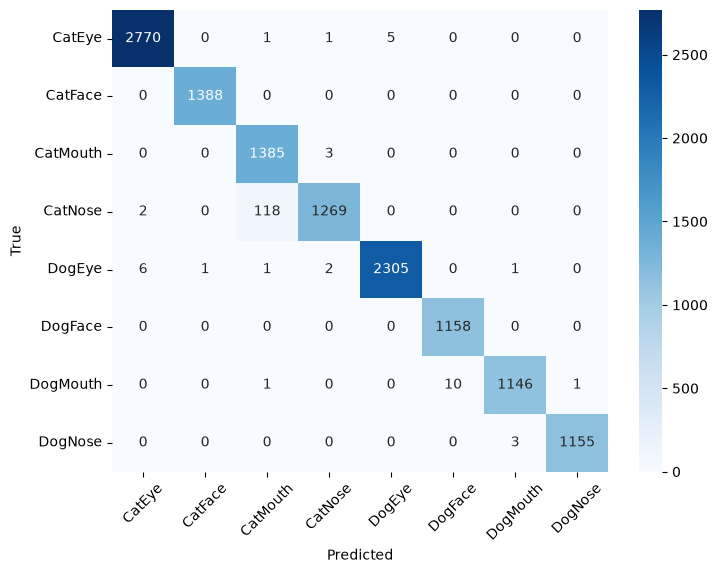

CatEye      0.997
CatFace     1.000
CatMouth    0.998
CatNose     0.914
DogEye      0.995
DogFace     1.000
DogMouth    0.990
DogNose     0.997
dtype: float64


In [ ]:
# Library for classification metrics for model evaluation
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict validation classes and compare them with the true labels
val_probs = predict_proba(val_loader)
preds, truth = val_probs.argmax(1), va_df["y"].values

print("Validation accuracy:", round(accuracy_score(truth, preds), 4))
print("Validation loss:", round(run_epoch(val_loader, False, criterion=val_loss_fn)[0], 4))
print(classification_report(truth, preds, target_names=classes, digits=3))

# Confusion matrix to examine class-level errors
cm = confusion_matrix(truth, preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.xticks(rotation=45); plt.show()

print(pd.Series(cm.diagonal() / cm.sum(axis=1), index=classes).round(3))

Total validation mistakes: 156


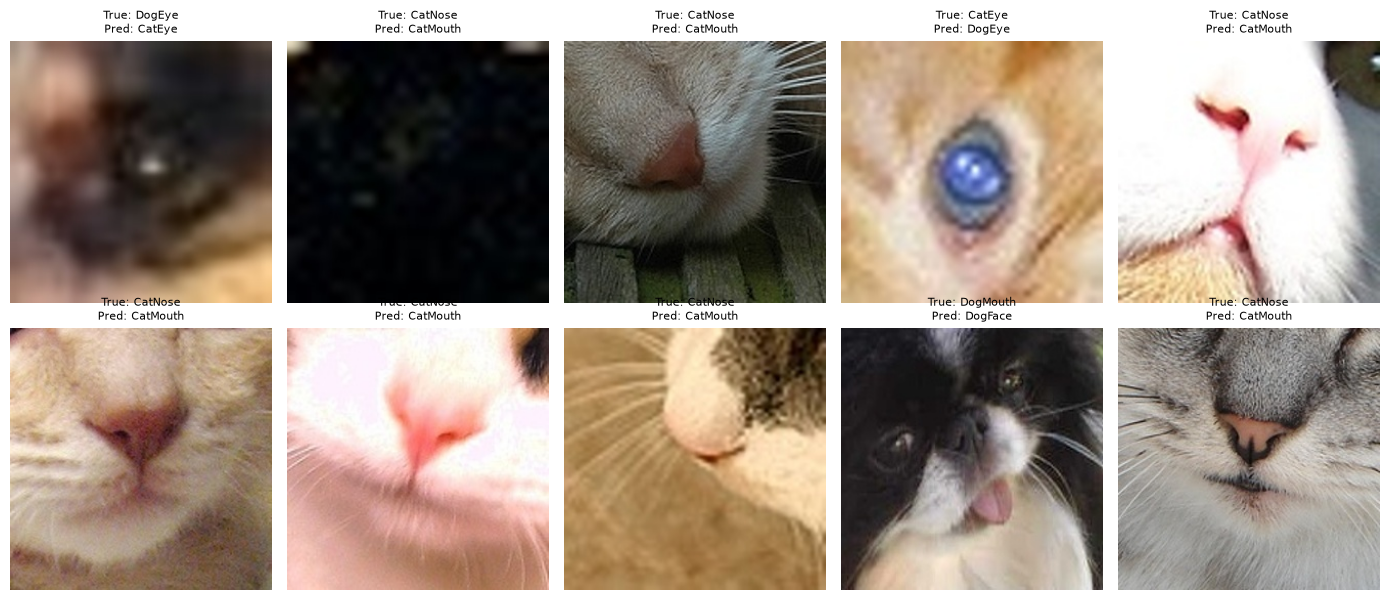

In [ ]:
# Identify and display up to ten incorrectly classified validation images
wrong = np.where(preds != truth)[0][:10]
print("Total validation mistakes:", (preds != truth).sum())
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(Image.open(va_df["path"][i]).convert("RGB"))
    ax.set_title(f"True: {classes[truth[i]]}\nPred: {classes[preds[i]]}", fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
# Test dataset in the original order of Kaggle submission 
test_df = pd.DataFrame({"path": [test_small[int(i)] for i in sample_sub[sub_id_col]],
                        "y": -1})             
                   
# Test loader without shuffling images
test_loader = DataLoader(ImgDS(test_df, eval_tf), batch_size=BATCH, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

# Predict test classes and fill submission template
test_probs = predict_proba(test_loader)
submission = sample_sub.copy()
submission[sub_class_col] = [classes[i] for i in test_probs.argmax(1)]

# Save final predictions to required format
submission.to_csv("submission.csv", index=False)

print(len(submission), "rows saved")
print(submission[sub_class_col].value_counts())

29443 rows saved
class
CatEye      6363
DogEye      5519
CatMouth    3594
CatFace     3111
DogMouth    2828
DogFace     2818
DogNose     2628
CatNose     2582
Name: count, dtype: int64
